# Figure 2: vertex populations during field rotation

This notebook reproduces the six-panel data plot for Fig. 2 from the original
300 K simulations. The columns compare 10 and 20 mT; the rows group vertices
by charge magnitude. The layout, selected rotation rates, and plotting style
are retained from the paper notebook. The vertex drawings above the panels in
the assembled paper figure are not generated here.

Run the cells in order. They read the existing local summary CSV, select the
plotted frequencies, and save the plot as PDF and PNG. No simulations or raw
trajectory processing are needed.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import display

In [2]:
plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    'font.family': 'serif',
    'text.usetex': True,
    'pgf.rcfonts': False,
    'xtick.labelsize':10,
    'ytick.labelsize':10,
    'axes.labelsize':11,
})

In [3]:
# locate the checkout from either the notebook directory or the project root.
working_directory = Path.cwd().resolve()
repo_candidates = [working_directory, *working_directory.parents, working_directory / "repo"]
REPO = next(path for path in repo_candidates
            if (path / "src/notebooks/figure2.ipynb").is_file())
SIZE = 10
DATA_PATH = REPO / "data/test11" / str(SIZE)
INPUT_FILE = DATA_PATH / "average_counts.csv"
FIGURE_DIR = REPO / "data/figures/paper"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Input: {INPUT_FILE}")
print(f"Output: {FIGURE_DIR}")

Input: /home/holo/documents/mnt/frequencygs/repo/data/test11/10/average_counts.csv
Output: /home/holo/documents/mnt/frequencygs/repo/data/figures/paper


## Data and conventions

`average_counts.csv` contains the fractions of the six vertex classes I–VI,
already averaged over the simulation realizations. This is the historical
paper dataset for a 10 × 10 vertex lattice (100 vertices and 200 particles).
We use these saved fractions directly, without pooling them with the newer
temperature campaigns.

The plotted groups are:

| Row | Vertex classes | Charge |
| --- | --- | --- |
| Top | I + VI | $q=\pm4$ |
| Middle | II + V | $q=\pm2$ |
| Bottom | III + IV | $q=0$ |

The field rotates through $90^\circ$ in a duration $\tau$, so
$\omega=\pi/(2\tau)$ and the horizontal coordinate is $\omega t$, displayed
in degrees. The inherited calculation rounds $\omega$ to four decimal places
before computing the angle; this convention is retained to reproduce the
existing plot. Numerical frequencies are angular rates in rad s$^{-1}$;
the legacy colorbar text is retained unchanged in this figure.

## Load the population time series

The fractions at a given field and time sum to one. The short checks below
verify the table layout and normalization before plotting. `total_time` is the
rotation duration in seconds; `time` is the observation time within that run.

In [4]:
raw_data = pd.read_csv(INPUT_FILE, index_col=["field", "time"])
classes = ["I", "II", "III", "IV", "V", "VI"]
assert set(classes + ["total_time"]).issubset(raw_data.columns)
assert np.isfinite(raw_data[classes].to_numpy()).all()
assert raw_data[classes].ge(0).all().all() and raw_data[classes].le(1).all().all()
assert np.allclose(raw_data[classes].sum(axis=1), 1)
assert {10, 20}.issubset(raw_data.index.get_level_values("field"))

omega = np.pi / 2 / raw_data.total_time.to_numpy()
raw_data["omega"] = np.around(omega, 4)
raw_data["theta"] = raw_data.index.get_level_values("time") * raw_data.omega
print(f"Loaded {len(raw_data):,} time samples at "
      f"{raw_data.index.get_level_values('field').nunique()} fields.")
display(raw_data.head(3))

Loaded 302,400 time samples at 21 fields.


I   II  III   IV    V   VI  total_time   omega    theta
field time                                                           
20    0.00  0.0  0.0  1.0  0.0  0.0  0.0           1  1.5708  0.00000
      0.05  0.0  0.0  1.0  0.0  0.0  0.0           1  1.5708  0.07854
      0.10  0.0  0.0  1.0  0.0  0.0  0.0           1  1.5708  0.15708

In [5]:
# keep the original selection, including its low-frequency subsampling order.
ws = raw_data.omega.unique()
ws = np.sort(np.concatenate((ws[ws <= 0.2][::5], ws[(ws > 0.2) & (ws <= 0.4)])))
selected_rates = (raw_data[["total_time", "omega"]].drop_duplicates()
                  .query("omega in @ws").sort_values("omega"))
assert not selected_rates.omega.duplicated().any()
display(selected_rates.rename(columns={"total_time": "rotation duration [s]",
                                      "omega": "omega [rad s^-1]"}))

rotation duration [s]  omega [rad s^-1]
field time                                         
19    0.0                    1000            0.0016
20    0.0                      50            0.0314
      0.0                      18            0.0873
      0.0                      13            0.1208
      0.0                       8            0.1963
      0.0                       7            0.2244
      0.0                       6            0.2618
      0.0                       5            0.3142
      0.0                       4            0.3927

## Plot the original two-field comparison

Below $0.2$ rad s$^{-1}$, the original selection keeps every fifth available
frequency in the CSV order; above it, all sampled rates up to $0.4$ rad s$^{-1}$
are shown. Sorting the selected rates only sets their plotting order. The same
selection is used in both field columns.

Each curve follows a charge-group population during the rotation. Color encodes
rotation rate, from red for slow rotation to green for fast rotation. The dashed
horizontal reference marks a population of one. The axes show the part of the
rotation from approximately $30^\circ$ to $90^\circ$. The colored row backgrounds
match the charge groups used in the paper.

The original sizing correction is retained so the cropped six-panel plot has
the intended paper-column dimensions. The export stem remains `fig2_raw`, since
the vertex illustrations in the assembled Fig. 2 are supplied separately.

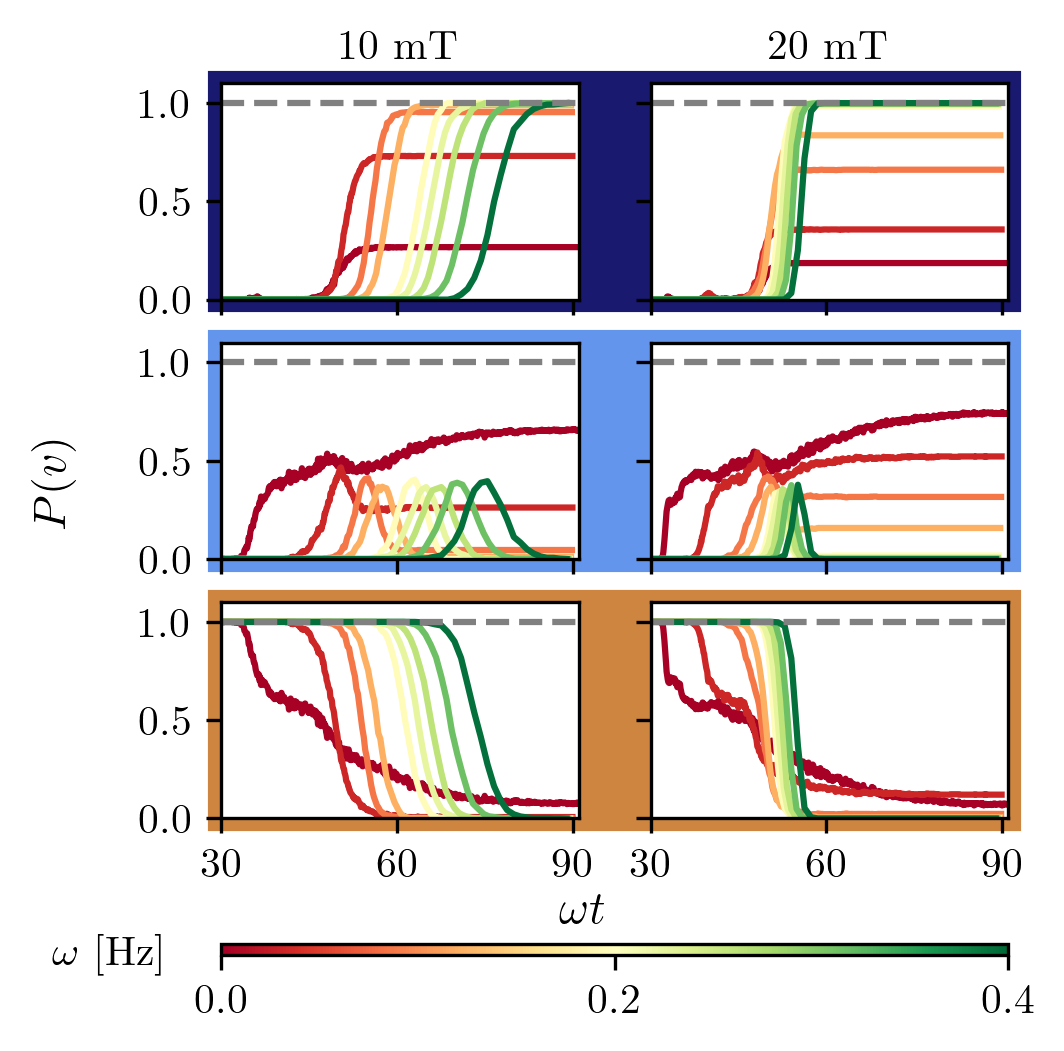

In [6]:
# the figure must be 245.52 total from 3.41 wide
# after saving it crops to 221.761
# so we need to add extra 23.759 pt to compensate, divided by 72
# 1pt = 1/72 in
# that is 0.32 in
COL = 246/72
OFFSET = (245.52-221.761)/72

fig, axes = plt.subplots(3, 2, figsize=(COL+OFFSET,3.5), dpi=300)

norm = plt.Normalize(min(ws),max(ws))
norm = plt.Normalize(0,0.4)
cmap = plt.get_cmap('RdYlGn')

field_values = [10,20]

# ==========================================================================================================
# MAIN PLOTS
# ==========================================================================================================
 
# plotting the fields
for j,B in enumerate(field_values):
    # here j selects the column in which it is going to be plotted
    for i,(w,cdf_w) in enumerate(raw_data.groupby('omega')):
        if w in ws:
            cdf_wB = cdf_w.xs(B,level='field')
            
            axes[0][j].plot(cdf_wB.theta*180/np.pi,cdf_wB.I + cdf_wB.VI, color = cmap(norm(w)))
            axes[0][j].set_title(f'${B}$ mT',fontsize=10)
            
            axes[1][j].plot(cdf_wB.theta*180/np.pi,cdf_wB.II + cdf_wB.V, color = cmap(norm(w)))
            
            axes[2][j].plot(cdf_wB.theta*180/np.pi,cdf_wB.III + cdf_wB.IV, color = cmap(norm(w)))


# adjusting the ticks and axes
for i in range(3):
    for j in range(2):
        axes[i][j].set_xlim(30,91)
        axes[i][j].set_ylim(0,1.1)
        
        axes[i][j].set_xticks([30,60,90])
        axes[i][j].set_yticks([0,0.5,1])
        
        axes[i][j].axhline(1, color ='gray', linestyle='--')
        
        
        if i<2:
            axes[i][j].set_xticklabels([])
            
        if j>0:
            axes[i][j].set_yticklabels([])

# ==========================================================================================================
# COLORBAR
# ==========================================================================================================

# putting a colorbar
fig.text(0.5,0.08,'$\\omega t$', fontsize=11)
fig.text(0.05, 0.5, '$P(v)$', ha='center', va='center', rotation=90, fontsize=11)
           
fig.subplots_adjust(bottom=0.18)  # Adjust the bottom space to make room for the colorbar
fig.subplots_adjust(left=0.2)  # Adjust the bottom space to make room for the shared axis label

cbar_ax = fig.add_axes([0.2, 0.05, 0.7, 0.01])  # [left, bottom, width, height]
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Set an empty array to the ScalarMappable

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
#cbar.set_label(label='$\\omega$ [Hz]', fontsize=10)
cbar.ax.tick_params(labelsize=10)

custom_ticks = np.round(np.array([min(ws), (min(ws)+max(ws)/2) ,max(ws)]),3)
custom_ticks = np.round(np.array([0,0.2,0.4]),3)
cbar.set_ticks(custom_ticks)
cbar.set_ticklabels(custom_ticks)

fig.text(0.1, 0.05, '$\\omega$ [Hz]', fontsize=10, ha='center', va='center')

# ==========================================================================================================
# BACKGROUND COLORBOXES
# ==========================================================================================================

# Colors for each row
colors = ['#191970', '#6495ed', '#cd853f']

width = 0.7
pad = 0.01
for i in range(3):
    pos = axes[i][0].get_position()
    x, y = pos.x0, pos.y0
    height = pos.y1 - pos.y0
    fig.add_artist(
        patches.Rectangle(
            (x-pad, y-pad), width+2*pad, height+2*pad, color=colors[i], alpha=1, transform=fig.transFigure, zorder=0)
    )

plt.show()

for suffix in ["pdf", "png"]:
    fig.savefig(FIGURE_DIR / f"fig2_raw.{suffix}", dpi=300,
                bbox_inches="tight", pad_inches=0)


## Saved figure

The displayed plot is saved as `repo/data/figures/paper/fig2_raw.pdf` and
`fig2_raw.png`. Re-running the notebook replaces these outputs. The original
version remains available on the `paper-v0` branch.